In [20]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader

In [21]:
from torch.accelerator import is_available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"you are using: {device}")

you are using: cuda


In [22]:
import idx2numpy
import torch

df = idx2numpy.convert_from_file(
    "/content/t10k-images.idx3-ubyte"
)

df.shape




labels = idx2numpy.convert_from_file("/content/t10k-labels-idx1-ubyte")

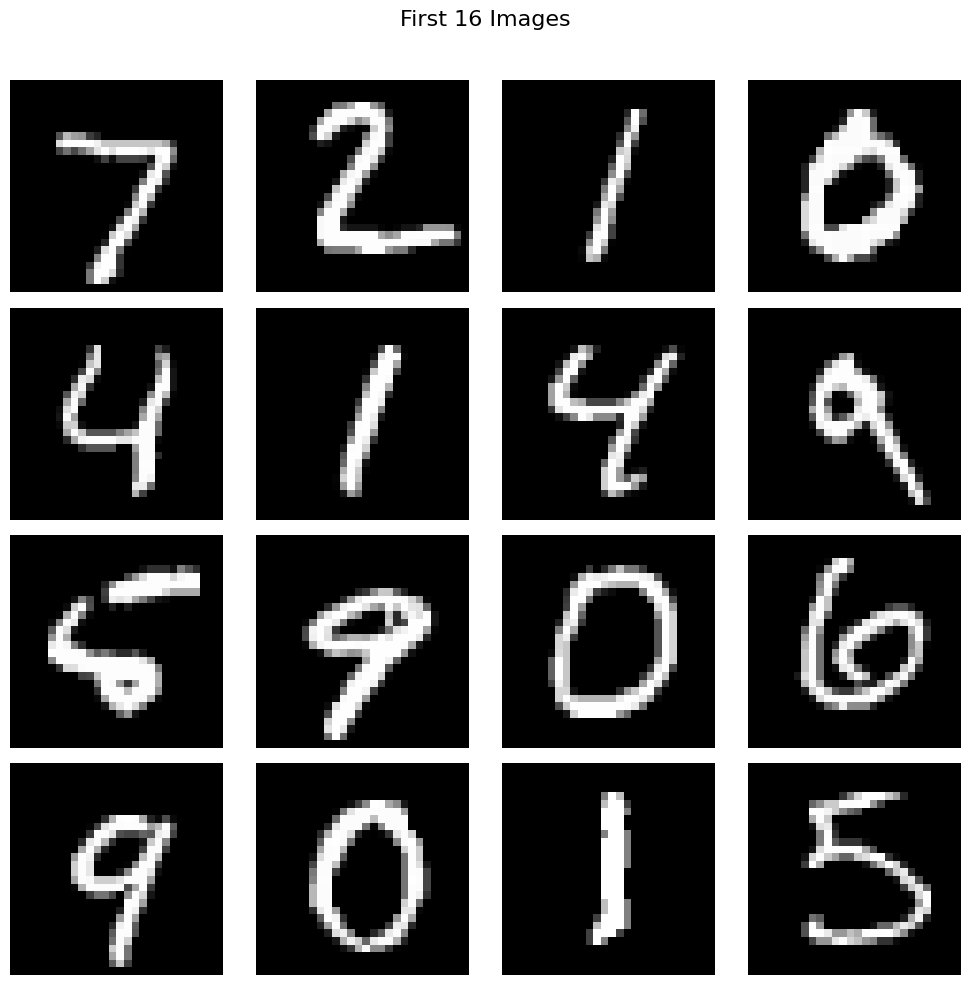

In [23]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("First 16 Images", fontsize=16)

for i, ax in enumerate(axes.flat):

    img = df[i]

    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.axis("off")


plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [24]:
!wget https://storage.googleapis.com/cvdf-datasets/mnist/t10k-labels-idx1-ubyte.gz

--2026-11-03 17:14:40--  https://storage.googleapis.com/cvdf-datasets/mnist/t10k-labels-idx1-ubyte.gz
Resolving storage.googleapis.com (storage.googleapis.com)... 34.3.1.27, 104.154.124.27, 104.154.125.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|34.3.1.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4542 (4.4K) [application/x-gzip]
Saving to: ‘t10k-labels-idx1-ubyte.gz’

t10k-labels-idx1-ub 100%[===================>]   4.44K  --.-KB/s    in 0s      

2026-11-03 17:14:40 (64.2 MB/s) - ‘t10k-labels-idx1-ubyte.gz’ saved [4542/4542]



In [25]:
!gunzip t10k-labels-idx1-ubyte.gz

gzip: t10k-labels-idx1-ubyte already exists; do you wish to overwrite (y or n)? y


In [26]:
labels = idx2numpy.convert_from_file(
    "/content/t10k-labels-idx1-ubyte"
)


X = df.reshape(df.shape[0], -1)
y = labels

In [27]:
y.shape

(10000,)

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [29]:
X_train.shape[1]

784

In [30]:
y.shape

(10000,)

In [31]:
y.shape[0]

10000

In [32]:
X_train = X_train/255.0
X_test = X_test/255.0

In [33]:
class CustomDataset(Dataset):
  def __init__(self, features, labels):
    super().__init__()


    self.features = torch.tensor(features, dtype=torch.float32)
    self.labels = torch.tensor(labels, dtype=torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self,index):
    return self.features[index], self.labels[index]

In [34]:
train_dataset = CustomDataset(X_train, y_train)
test_dataset = CustomDataset(X_test, y_test)

In [35]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory=True)

In [36]:
len(train_loader)

250

In [37]:
len(test_loader)

63

In [38]:
class MyNN(nn.Module):
  def __init__(self, num_features):
    super().__init__()

    self.model = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10)

    )

  def forward(self, x):
    return self.model(x)

In [39]:
model = MyNN(X_train.shape[1])

In [40]:
model.parameters()
model.to(device)
epochs =100
learning_rate = 0.01
critrion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

In [41]:
for epoch in range(epochs):

  total_epoch_loss = 0
  for batch_features, batch_labels in train_loader:

    batch_features,batch_labels = batch_features.to(device), batch_labels.to(device)


    outputs = model(batch_features)

    loss = critrion(outputs, batch_labels)

    optimizer.zero_grad()


    loss.backward()


    optimizer.step()


    total_epoch_loss = total_epoch_loss + loss.item()

  avg_loss = total_epoch_loss / len(train_loader)

  print(f"epoch {epoch+1} loss {avg_loss}")

epoch 1 loss 2.258590001106262
epoch 2 loss 2.0039545545578004
epoch 3 loss 1.3554509382247926
epoch 4 loss 0.8371876196861268
epoch 5 loss 0.6193869701623916
epoch 6 loss 0.515125143289566
epoch 7 loss 0.45263316071033477
epoch 8 loss 0.411402134001255
epoch 9 loss 0.380577129304409
epoch 10 loss 0.3567075478732586
epoch 11 loss 0.33908071073889734
epoch 12 loss 0.3228398255705833
epoch 13 loss 0.3095200620889664
epoch 14 loss 0.2981454606205225
epoch 15 loss 0.2873761761188507
epoch 16 loss 0.2780361942797899
epoch 17 loss 0.2700640856921673
epoch 18 loss 0.26151504391431807
epoch 19 loss 0.25378651106357575
epoch 20 loss 0.24678277967870235
epoch 21 loss 0.24026653258502484
epoch 22 loss 0.2337617812305689
epoch 23 loss 0.2277855142802
epoch 24 loss 0.221408626511693
epoch 25 loss 0.21598640908300876
epoch 26 loss 0.21092124535143375
epoch 27 loss 0.20467942509055137
epoch 28 loss 0.199044928714633
epoch 29 loss 0.194385002925992
epoch 30 loss 0.18984543730318545
epoch 31 loss 0.184

In [42]:
batch_features.shape[1]

784

In [43]:
model.eval()

MyNN(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [44]:

total = 0
correct = 0

with torch.no_grad():
  for batch_features, batch_labels in test_loader:

    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    output = model(batch_features)
    _,predicted = torch.max(output, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

0.947


In [45]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 9.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [46]:
from torchmetrics.classification import MulticlassAccuracy

accuracy = MulticlassAccuracy(num_classes=10).to(device)

with torch.no_grad():
    for batch_features, batch_labels in test_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        output = model(batch_features)

        accuracy.update(output, batch_labels)

print("Accuracy:", accuracy.compute().item())

Accuracy: 0.9469712972640991


In [47]:

total = 0
correct = 0

with torch.no_grad():
  for batch_features, batch_labels in train_loader:

    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    output = model(batch_features)
    _,predicted = torch.max(output, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

0.9975


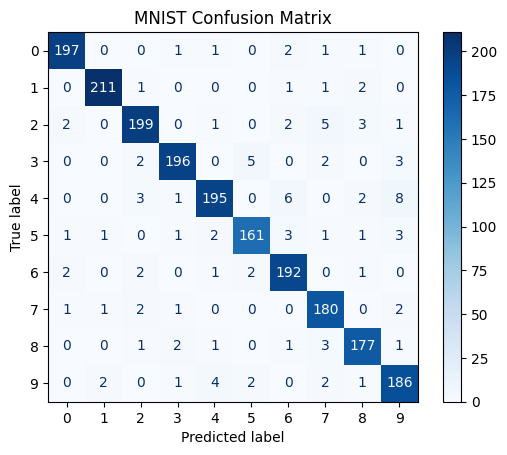

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

all_preds = []
all_labels = []

model.eval()

with torch.no_grad():
    for batch_features, batch_labels in test_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        output = model(batch_features)
        _, predicted = torch.max(output, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(batch_labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap="Blues")
plt.title("MNIST Confusion Matrix")
plt.show()

In [49]:
torch.save(model.state_dict(), "mnist_model.pth")

In [51]:
loaded_model = MyNN(X_train.shape[1]).to(device)

loaded_model.load_state_dict(
    torch.load("mnist_model.pth", map_location=device)
)

loaded_model.eval()
sample = torch.tensor(
    X_test[0],
    dtype=torch.float32
).unsqueeze(0).to(device)

In [52]:



with torch.no_grad():
    output = loaded_model(sample)

    predicted = torch.argmax(output, dim=1)

    print("Predicted:", predicted.item())
    print("Actual:", y_test[0])

Predicted: 6
Actual: 6


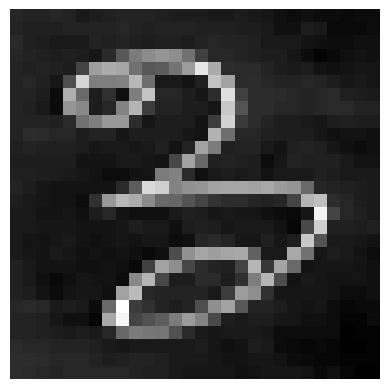

In [53]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img = Image.open("/content/3pic.jpeg").convert("L")

img = img.resize((28, 28))

img_array = np.array(img)

# White background to black
img_array = 255 - img_array

img_array = img_array.astype("float32") / 255.0

plt.imshow(img_array, cmap="gray")
plt.axis("off")
plt.show()

In [54]:
img_array = 255 - img_array

img_array = img_array.astype("float32") / 255.0

img_array = img_array.reshape(1, 784)

sample = torch.tensor(img_array, dtype=torch.float32).to(device)

In [55]:
loaded_model.eval()

with torch.no_grad():
    output = loaded_model(sample)

    predicted = torch.argmax(output, dim=1)

    print("Predicted Digit:", predicted.item())

Predicted Digit: 3


In [56]:
loaded_model.eval()

with torch.no_grad():
    output = loaded_model(sample)

    probabilities = torch.softmax(output, dim=1)

    confidence, predicted = torch.max(probabilities, dim=1)

    print("Predicted Digit:", predicted.item())
    print("Confidence:", f"{confidence.item()*100:.2f}%")

Predicted Digit: 3
Confidence: 76.98%


In [59]:
import os

print(os.listdir("/content"))

['.config', 'mnist_model.pth', 'MNIST-Handwritten-Digit-Classification.ipynb', '3pic.jpeg', 't10k-labels-idx1-ubyte', '.ipynb_checkpoints', 't10k-images.idx3-ubyte', 'sample_data']


In [60]:
torch.save(
    loaded_model.state_dict(),
    "/content/mnist_model.pth"
)

In [61]:
from google.colab import files

files.download("/content/mnist_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>